# Chinese world: trends by the dates used

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'
POLITY_DB_PATH = '../../data/cultura/humans_clean_enriched_v3.duckdb'

FIRST_YEAR, LAST_YEAR = -500, 1900
PRECISE = ['day', 'month', 'year']

COARSE_COLORS = {'Precise dates only': NAVY, 'With coarse dates (century)': ORANGE}
STAGE_COLORS = {'Birth': ORANGE, 'Active life': BLUE, 'Late life': GREEN}
LEGEND_FONTSIZE = 15

apply_style()

## Load data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"ATTACH '{POLITY_DB_PATH}' AS polity_db (READ_ONLY)")

chinese_polities = con.sql('''
    SELECT DISTINCT name, entity.qid AS polity_qid
    FROM   polity_db.polity
    WHERE  list_contains(world, 'Chinese world') AND entity.qid IS NOT NULL
''').pl()

individuals = con.sql('''
    WITH chinese AS (
        SELECT DISTINCT entity.qid AS qid
        FROM   (SELECT entity, unnest(country_of_citizenship) AS citizenship FROM individual)
        WHERE  citizenship.entity.qid IN (SELECT polity_qid FROM chinese_polities)
    )
    SELECT entity.qid                AS qid,
           birth_date.year           AS birth_year,
           birth_date.precision      AS birth_precision,
           birth_date.field_provenance['year'].rule ILIKE '%gives only%' AS birth_from_coarse,
           death_date.year           AS death_year,
           death_date.precision      AS death_precision,
           death_date.field_provenance['year'].rule ILIKE '%gives only%' AS death_from_coarse,
           coalesce(birth_date.coarse_label, death_date.coarse_label) AS coarse_label,
           first_work_date.year      AS active_life_start,
           last_work_date.year       AS active_life_end,
           first_work_date.source    AS active_life_source,
           first_work_date.precision AS work_precision
    FROM   individual_enriched
    WHERE  entity.qid IN (SELECT qid FROM chinese)
''').pl().with_columns(pl.col('birth_from_coarse', 'death_from_coarse').fill_null(False))
con.close()

assert individuals['qid'].n_unique() == individuals.height
print(f'{chinese_polities.height} Chinese-world polities with a Wikidata item')
print(f'{individuals.height:,} Chinese-world individuals by citizenship')
individuals.sample(5, seed=0)

24 Chinese-world polities with a Wikidata item
287,101 Chinese-world individuals by citizenship


qid,birth_year,birth_precision,birth_from_coarse,death_year,death_precision,death_from_coarse,coarse_label,active_life_start,active_life_end,active_life_source,work_precision
str,i64,str,bool,i64,str,bool,str,i64,i64,str,str
"""Q45640063""",null,null,false,null,null,false,null,null,null,null,null
"""Q45666830""",null,null,false,null,null,false,null,null,null,null,null
"""Q45656315""",null,null,false,null,null,false,null,null,null,null,null
"""Q45705559""",null,null,false,null,null,false,null,null,null,null,null
"""Q45498034""",1429,"""year""",false,1488,"""year""",false,null,1459,1481,"""estimated""","""year"""


## Preprocessing
### Coarse or precise

In [3]:
def is_coarse(prefix):
    return ~pl.col(f'{prefix}_precision').is_in(PRECISE).fill_null(False) | pl.col(f'{prefix}_from_coarse')


def label_century(label):
    number = label.str.extract(r'^(\d+)').cast(pl.Int64)
    start = (number - 1) * 100
    return pl.when(label.str.ends_with('BC')).then(-start - 100).otherwise(start)


individuals = individuals.with_columns(
    (pl.col('active_life_start').is_not_null() & (
        (pl.col('work_precision') != 'year') | ((pl.col('active_life_source') == 'estimated') & is_coarse('birth'))
    )).alias('active_life_coarse'),
    (is_coarse('birth') | is_coarse('death')).alias('life_coarse'),
)

active_lives = individuals.filter(pl.col('active_life_start').is_not_null() & pl.col('active_life_end').is_not_null())
coarse_only = individuals.filter(
    pl.col('active_life_start').is_null() & pl.col('coarse_label').is_not_null() & ~pl.col('coarse_label').str.contains('millennium')
).with_columns(label_century(pl.col('coarse_label')).alias('century'))
millennium_only = individuals.filter(pl.col('active_life_start').is_null() & pl.col('coarse_label').str.contains('millennium'))

assert (active_lives['active_life_end'] >= active_lives['active_life_start']).all()
assert pl.select(label_century(pl.lit('16th AC'))).item() == 1500
assert pl.select(label_century(pl.lit('2nd BC'))).item() == -200
print(f"active lives: {active_lives.height:,} — precise {(~active_lives['active_life_coarse']).sum():,}, coarse {active_lives['active_life_coarse'].sum():,}")
print(f'only a coarse century, no active life: {coarse_only.height:,}')
print(f'only a coarse millennium, removed: {millennium_only.height:,}')
coarse_only.select('qid', 'coarse_label', 'century').head()

active lives: 84,349 — precise 83,602, coarse 747
only a coarse century, no active life: 436
only a coarse millennium, removed: 5


qid,coarse_label,century
str,str,i64
"""Q10566068""","""8th AC""",700
"""Q10566570""","""4th AC""",300
"""Q10566824""","""6th AC""",500
"""Q10720375""","""8th AC""",700
"""Q11477154""","""6th AC""",500


### Individuals per period

In [4]:
def individuals_per_period(frame, start, end, period):
    return (
        frame.select('qid', pl.int_ranges((pl.col(start) // period) * period, (pl.col(end) // period) * period + 1, period).alias('period'))
        .explode('period')
        .filter(pl.col('period').is_between(FIRST_YEAR, LAST_YEAR - period))
        .group_by('period').agg(pl.col('qid').n_unique().alias('individuals'))
        .sort('period')
    )


def fill_periods(counts, period):
    periods = pl.DataFrame({'period': np.arange(FIRST_YEAR, LAST_YEAR, period)})
    return periods.join(counts, on='period', how='left').with_columns(pl.col('individuals').fill_null(0))

### Active individuals per century, with and without coarse dates

In [5]:
precise_active = active_lives.filter(~pl.col('active_life_coarse'))
coarse_rows = pl.concat([
    active_lives.select('qid', 'active_life_start', 'active_life_end'),
    coarse_only.select('qid', pl.col('century').alias('active_life_start'), pl.col('century').alias('active_life_end')),
])

per_century = (
    fill_periods(individuals_per_period(precise_active, 'active_life_start', 'active_life_end', 100), 100)
    .rename({'individuals': 'Precise dates only'})
    .join(fill_periods(individuals_per_period(coarse_rows, 'active_life_start', 'active_life_end', 100), 100)
          .rename({'individuals': 'With coarse dates (century)'}), on='period')
    .with_columns((pl.col('With coarse dates (century)') - pl.col('Precise dates only')).alias('added by coarse dates'))
)
assert (per_century['added by coarse dates'] >= 0).all()
with pl.Config(tbl_rows=30):
    display(per_century)

period,Precise dates only,With coarse dates (century),added by coarse dates
i64,u32,u32,u32
-500,5,5,0
-400,2,5,3
-300,18,31,13
-200,4,5,1
-100,1,2,1
0,14,19,5
100,0,0,0
200,19,36,17
300,55,84,29


### Born, active and in late life per decade

In [6]:
same_people = active_lives.filter(
    pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null()
    & ~pl.col('life_coarse') & ~pl.col('active_life_coarse')
    & (pl.col('death_year') >= pl.col('active_life_end'))
)
print(f'{same_people.height:,} of {active_lives.height:,} active lives kept (precise birth, active life and death)')

per_decade = (
    fill_periods(individuals_per_period(same_people, 'birth_year', 'birth_year', 10), 10).rename({'individuals': 'Birth'})
    .join(fill_periods(individuals_per_period(same_people, 'active_life_start', 'active_life_end', 10), 10)
          .rename({'individuals': 'Active life'}), on='period')
    .join(fill_periods(individuals_per_period(same_people, 'active_life_end', 'death_year', 10), 10)
          .rename({'individuals': 'Late life'}), on='period')
)
per_decade.filter(pl.col('period').is_between(1600, 1700))

83,415 of 84,349 active lives kept (precise birth, active life and death)


period,Birth,Active life,Late life
i64,u32,u32,u32
1600,742,1819,1595
1610,1116,1501,1366
1620,1332,1549,837
1630,960,1922,985
1640,717,2397,1260
…,…,…,…
1660,622,3435,1552
1670,735,3204,2171
1680,834,2542,2265


## Figures
### Figure 1: Active individuals per century, with and without coarse dates

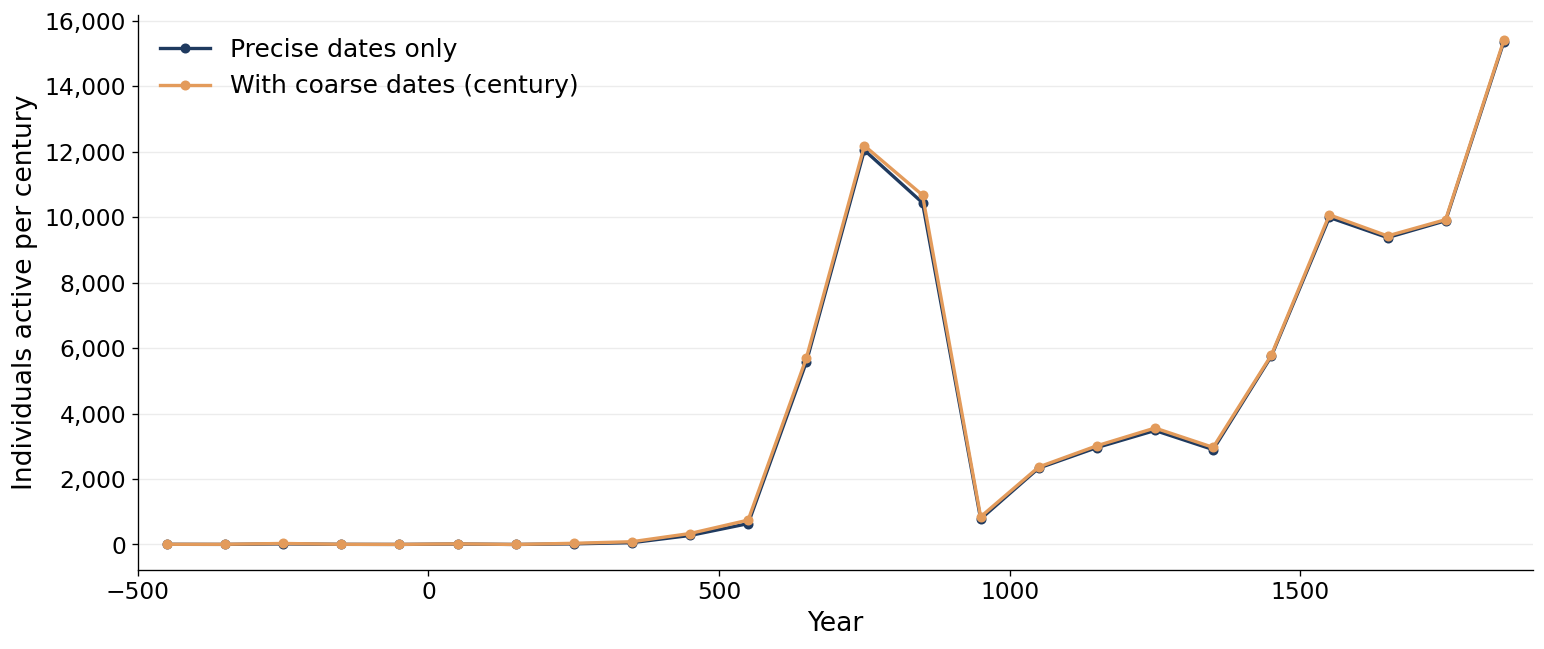

In [7]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for column, color in COARSE_COLORS.items():
    ax.plot(per_century['period'] + 50, per_century[column], color=color, marker='o', markersize=5, label=column)
ax.set_xlim(FIRST_YEAR, LAST_YEAR)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Year')
ax.set_ylabel('Individuals active per century')
ax.grid(axis='y')
ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
plt.show()

### Figure 2: Individuals born, active and in late life per decade

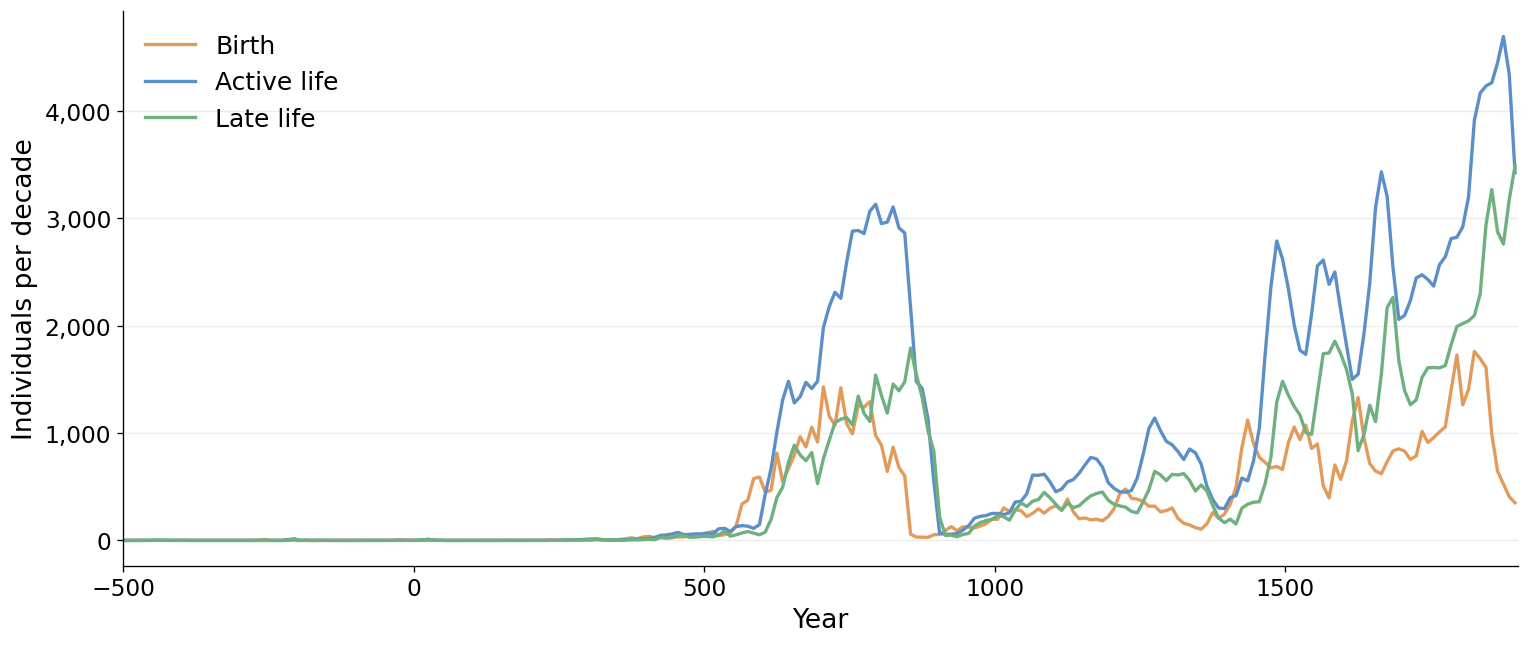

In [8]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for column, color in STAGE_COLORS.items():
    ax.plot(per_decade['period'] + 5, per_decade[column], color=color, label=column)
ax.set_xlim(FIRST_YEAR, LAST_YEAR)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel('Year')
ax.set_ylabel('Individuals per decade')
ax.grid(axis='y')
ax.legend(loc='upper left', fontsize=LEGEND_FONTSIZE)
plt.show()